In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from stats_toolkit import pearson_r, correlation_summary

rr = pd.read_csv("../data/raw/gaia_dr3_rrlyrae_sample_ri20M_raw.csv")
rr["period"] = rr["pf"].fillna(rr["p1_o"])
rr["period_type"] = np.where(rr["pf"].notna(), "fundamental", "overtone")
rr["log_period"] = np.log10(rr["period"])

print(rr.shape, "| duplicate source_ids:", rr["source_id"].duplicated().sum())
print(rr["period_type"].value_counts())
print()
print(rr.isna().mean().round(3))
print()
print(rr[["log_period", "peak_to_peak_g", "phot_g_mean_mag", "bp_rp"]].describe().round(3))

(2000, 12) | duplicate source_ids: 0
period_type
fundamental    1312
overtone        688
Name: count, dtype: int64

source_id              0.000
pf                     0.344
p1_o                   0.646
peak_to_peak_g         0.000
num_clean_epochs_g     0.000
random_index           0.000
phot_g_mean_mag        0.000
bp_rp                  0.063
parallax_over_error    0.026
period                 0.000
period_type            0.000
log_period             0.000
dtype: float64

       log_period  peak_to_peak_g  phot_g_mean_mag     bp_rp
count    2000.000        2000.000         2000.000  1874.000
mean       -0.337           0.568           18.227     1.168
std         0.138           0.269            1.828     0.730
min        -0.686           0.102           11.244    -1.247
25%        -0.470           0.358           16.782     0.632
50%        -0.290           0.495           18.474     0.862
75%        -0.227           0.763           19.747     1.604
max        -0.028           1.39

In [2]:
rr2 = rr.dropna(subset=["log_period", "peak_to_peak_g"])
groups = {"pooled": rr2,
          "fundamental": rr2[rr2["period_type"] == "fundamental"],
          "overtone": rr2[rr2["period_type"] == "overtone"]}

rows = []
for name, d in groups.items():
    s = correlation_summary(d["log_period"], d["peak_to_peak_g"])
    sp = stats.pearsonr(d["log_period"], d["peak_to_peak_g"])
    rows.append({"group": name, "n": s["n"], "r": s["r"], "r2": s["r2"],
                 "ci_low": s["ci95"][0], "ci_high": s["ci95"][1],
                 "scipy r": sp[0],
                 "spearman": stats.spearmanr(d["log_period"], d["peak_to_peak_g"])[0]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

f = groups["fundamental"]["peak_to_peak_g"]
o = groups["overtone"]["peak_to_peak_g"]
print()
print("mean amplitude: fundamental", round(f.mean(), 3), "| overtone", round(o.mean(), 3))
print("Welch t:", stats.ttest_ind(f, o, equal_var=False))

      group    n      r    r2  ci_low  ci_high  scipy r  spearman
     pooled 2000  0.411 0.169   0.374    0.447    0.411     0.334
fundamental 1312 -0.411 0.169  -0.455   -0.365   -0.411    -0.462
   overtone  688  0.222 0.049   0.150    0.292    0.222     0.220

mean amplitude: fundamental 0.681 | overtone 0.354
Welch t: TtestResult(statistic=np.float64(40.283867487354), pvalue=np.float64(2.5204921076144806e-255), df=np.float64(1851.0748789945972))


In [3]:
from stats_toolkit import partial_correlation

d = rr.dropna(subset=["log_period", "peak_to_peak_g", "phot_g_mean_mag", "bp_rp"])
print("n with all four variables:", len(d))

rows = []
for name, g in [("pooled", d),
                ("fundamental", d[d["period_type"] == "fundamental"]),
                ("overtone", d[d["period_type"] == "overtone"])]:
    raw = pearson_r(g["log_period"], g["peak_to_peak_g"])
    r, df, t, p = partial_correlation(g["log_period"], g["peak_to_peak_g"],
                                      g[["phot_g_mean_mag", "bp_rp"]])
    rows.append({"group": name, "n": len(g), "raw r": raw,
                 "partial r (control G, bp_rp)": r, "df": df, "t": t, "p": p})
print(pd.DataFrame(rows).round(4).to_string(index=False))

n with all four variables: 1874
      group    n   raw r  partial r (control G, bp_rp)   df        t   p
     pooled 1874  0.4060                        0.3897 1870  18.2983 0.0
fundamental 1254 -0.4113                       -0.4484 1250 -17.7355 0.0
   overtone  620  0.2154                        0.1671  616   4.2052 0.0


In [4]:
import statsmodels.api as sm

rows = []
for name, g in [("pooled", d),
                ("fundamental", d[d["period_type"] == "fundamental"]),
                ("overtone", d[d["period_type"] == "overtone"])]:
    X = sm.add_constant(g[["log_period", "phot_g_mean_mag", "bp_rp"]])
    fit = sm.OLS(g["peak_to_peak_g"], X).fit()
    t = fit.tvalues["log_period"]
    r_from_t = np.sign(t) * np.sqrt(t**2 / (t**2 + fit.df_resid))
    mine = partial_correlation(g["log_period"], g["peak_to_peak_g"],
                               g[["phot_g_mean_mag", "bp_rp"]])[0]
    rows.append({"group": name, "mine": mine, "from statsmodels t": r_from_t,
                 "difference": abs(mine - r_from_t)})
print(pd.DataFrame(rows).round(6).to_string(index=False))

      group      mine  from statsmodels t  difference
     pooled  0.389694            0.389694         0.0
fundamental -0.448382           -0.448382         0.0
   overtone  0.167053            0.167053         0.0


In [5]:
from stats_toolkit import vif
from statsmodels.stats.outliers_influence import variance_inflation_factor

d = d.copy()
d["overtone"] = (d["period_type"] == "overtone").astype(int)
preds = ["log_period", "bp_rp", "phot_g_mean_mag", "overtone"]

X = d[preds].to_numpy()
mine = vif(X)
Xc = sm.add_constant(d[preds]).to_numpy()
theirs = [variance_inflation_factor(Xc, i + 1) for i in range(len(preds))]

print(pd.DataFrame({"predictor": preds, "VIF (mine)": mine, "VIF (statsmodels)": theirs}).round(3).to_string(index=False))

fit = sm.OLS(d["peak_to_peak_g"], sm.add_constant(d[preds])).fit()
print()
print(fit.summary().tables[1])
print("R2 =", round(fit.rsquared, 3), "| adj R2 =", round(fit.rsquared_adj, 3),
      "| F =", round(fit.fvalue, 1), "| n =", int(fit.nobs))

      predictor  VIF (mine)  VIF (statsmodels)
     log_period       4.906              4.906
          bp_rp       1.154              1.154
phot_g_mean_mag       1.155              1.155
       overtone       4.868              4.868

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.7648      0.049     15.474      0.000       0.668       0.862
log_period         -1.1657      0.075    -15.620      0.000      -1.312      -1.019
bp_rp              -0.0674      0.007     -9.987      0.000      -0.081      -0.054
phot_g_mean_mag    -0.0161      0.003     -5.947      0.000      -0.021      -0.011
overtone           -0.6188      0.021    -28.786      0.000      -0.661      -0.577
R2 = 0.452 | adj R2 = 0.451 | F = 385.1 | n = 1874


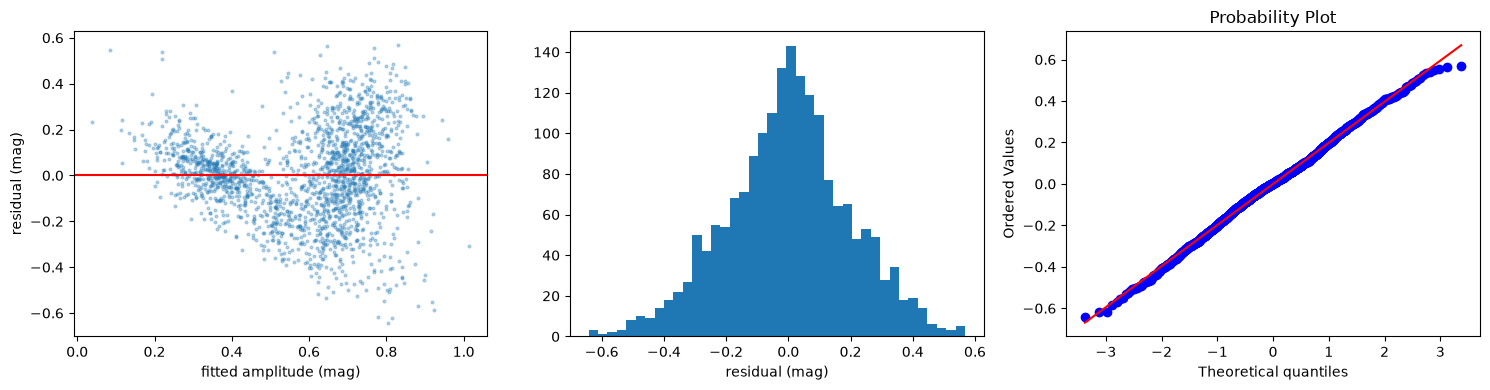

residual skewness: -0.072 | excess kurtosis: 0.038
Breusch-Pagan p: 5.1948221542432277e-45


In [6]:
from scipy import stats as st
res_ = fit.resid
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(fit.fittedvalues, res_, s=4, alpha=0.3)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("fitted amplitude (mag)")
ax[0].set_ylabel("residual (mag)")
ax[1].hist(res_, bins=40)
ax[1].set_xlabel("residual (mag)")
st.probplot(res_, dist="norm", plot=ax[2])
plt.tight_layout()
plt.show()

print("residual skewness:", round(st.skew(res_), 3), "| excess kurtosis:", round(st.kurtosis(res_), 3))
print("Breusch-Pagan p:", sm.stats.diagnostic.het_breuschpagan(res_, fit.model.exog)[1])